# Punto 3


Partimos de:

$$
U(x,y,t)=\sin(\pi x)\sin(\pi y)a(t),
\qquad
a''(t)+2\pi^2a(t)=0,
$$
con
$$
a(0)=1,\qquad a'(0)=\sqrt{2}\pi.
$$

La solución exacta usada para evaluar es
$$
a_{\rm exacta}(t)=\cos(\sqrt{2}\pi t)+\sin(\sqrt{2}\pi t).
$$






La frecuencia angular es $\omega=\sqrt{2}\pi$, y el período es $T=2\pi/\omega=\sqrt{2}$. Se estudian tres períodos.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

omega = np.sqrt(2) * np.pi
period = 2 * np.pi / omega
t_final = 3 * period

# Puntos de colocación para imponer la EDO
t_train = np.linspace(0.0, t_final, 300)
# Malla fina para graficar y evaluar
t = np.linspace(0.0, t_final, 1000)

print(f"Frecuencia angular = {omega:.8f}")
print(f"Período = {period:.8f}")
print(f"Tiempo final = {t_final:.8f}")

Frecuencia angular = 4.44288294
Período = 1.41421356
Tiempo final = 4.24264069


## 2. Solución analítica de referencia


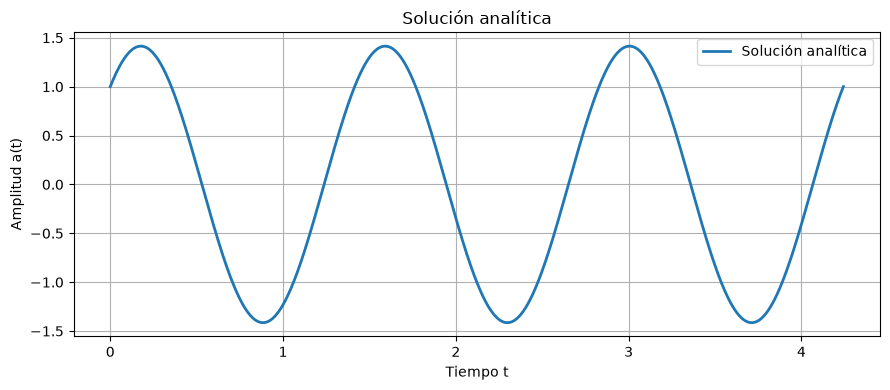

In [3]:
def a_exact(t):
    return np.cos(omega*t) + np.sin(omega*t)

a_reference = a_exact(t)

plt.figure(figsize=(9, 4))
plt.plot(t, a_reference, label="Solución analítica", linewidth=2)
plt.xlabel("Tiempo t")
plt.ylabel("Amplitud a(t)")
plt.title("Solución analítica")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## 3. Modelo A: dos neuronas sinusoidales en paralelo

$$
a_A(t)=A_1\sin(w_1t+b_1)+A_2\sin(w_2t+b_2).
$$

$$
a_A'(t)=\sum_{j=1}^2 A_jw_j\cos(w_jt+b_j),
\quad
a_A''(t)=-\sum_{j=1}^2 A_jw_j^2\sin(w_jt+b_j).
$$

El residuo de la EDO es $r_A(t)=a_A''(t)+2\pi^2a_A(t)$.

In [4]:
def model_A(p, t):
    A1, A2, w1, w2, b1, b2 = p
    return A1*np.sin(w1*t+b1) + A2*np.sin(w2*t+b2)

def model_A_d1(p, t):
    A1, A2, w1, w2, b1, b2 = p
    return A1*w1*np.cos(w1*t+b1) + A2*w2*np.cos(w2*t+b2)

def model_A_d2(p, t):
    A1, A2, w1, w2, b1, b2 = p
    return -A1*w1**2*np.sin(w1*t+b1) - A2*w2**2*np.sin(w2*t+b2)

def residual_A(p, t):
    return model_A_d2(p, t) + 2*np.pi**2*model_A(p, t)

def residual_vector_A(p):
    return np.concatenate([
        residual_A(p, t_train),
        [5*(model_A(p, 0.0)-1.0)],
        [5*(model_A_d1(p, 0.0)-omega)]
    ])



In [5]:
p0_A = np.array([1.25, 0.15, 1.04*omega, 0.85*omega,
                 np.pi/4 + 0.08, 0.40])

fit_A = least_squares(
    residual_vector_A, p0_A, max_nfev=10000, x_scale="jac",
    ftol=1e-12, xtol=1e-12, gtol=1e-12
)
params_A = fit_A.x

print("Convergencia:", fit_A.success)
print("Parámetros [A1, A2, w1, w2, b1, b2]:")
print(params_A)
print("Norma de residuos:", np.linalg.norm(fit_A.fun))

Convergencia: True
Parámetros [A1, A2, w1, w2, b1, b2]:
[ 1.41421356e+00 -2.24371128e-14  4.44288294e+00  4.17008762e+00
  7.85398163e-01  2.89997685e-01]
Norma de residuos: 1.5391942416994516e-12


## 4. Modelo B: dos capas consecutivas

$$
h_1(t)=\sin(w_1t+b_1),\qquad
a_B(t)=A\sin(w_2h_1(t)+b_2).
$$

Definimos $q=w_1t+b_1$ y $v=w_2\sin(q)+b_2$. Entonces

$$
a_B'(t)=Aw_1w_2\cos(v)\cos(q),
$$

$$
a_B''(t)=-Aw_1^2\left[
w_2^2\sin(v)\cos^2(q)+w_2\cos(v)\sin(q)
\right].
$$

El residuo es $r_B(t)=a_B''(t)+2\pi^2a_B(t)$.

In [10]:
def model_B(p, t):
    A, w1, b1, w2, b2 = p
    q = w1*t + b1
    return A*np.sin(w2*np.sin(q)+b2)

def model_B_d1(p, t):
    A, w1, b1, w2, b2 = p
    q = w1*t + b1
    v = w2*np.sin(q) + b2
    return A*w1*w2*np.cos(v)*np.cos(q)

def model_B_d2(p, t):
    A, w1, b1, w2, b2 = p
    q = w1*t + b1
    v = w2*np.sin(q) + b2
    return -A*w1**2 * (
        w2**2*np.sin(v)*np.cos(q)**2
        + w2*np.cos(v)*np.sin(q)
    )

def residual_B(p, t):
    return model_B_d2(p, t) + 2*np.pi**2*model_B(p, t)

def residual_vector_B(p):
    return np.concatenate([
        residual_B(p, t_train),
        [5*(model_B(p, 0.0)-1.0)],
        [5*(model_B_d1(p, 0.0)-omega)]
    ])

p0_B = np.array([7.1, omega, np.pi/4, 0.2, 0.0])


In [9]:

# Límites numéricos para estabilizar el ajuste; no son leyes físicas.
lower_B = [0.0, 0.1, -2*np.pi, 0.02, -2*np.pi]
upper_B = [100.0, 10.0, 2*np.pi, 1.0, 2*np.pi]

fit_B = least_squares(
    residual_vector_B, p0_B, bounds=(lower_B, upper_B),
    max_nfev=10000, x_scale="jac",
    ftol=1e-12, xtol=1e-12, gtol=1e-12
)
params_B = fit_B.x

print("Convergencia:", fit_B.success)
print("Parámetros [A, w1, b1, w2, b2]:")
print(params_B)
print("Norma de residuos:", np.linalg.norm(fit_B.fun))

Convergencia: True
Parámetros [A, w1, b1, w2, b2]:
[7.07138540e+01 4.44288192e+00 7.85344978e-01 2.00000000e-02
 6.38926451e-09]
Norma de residuos: 0.045586641621386224


## 5. Gráficas de las soluciones y residuos


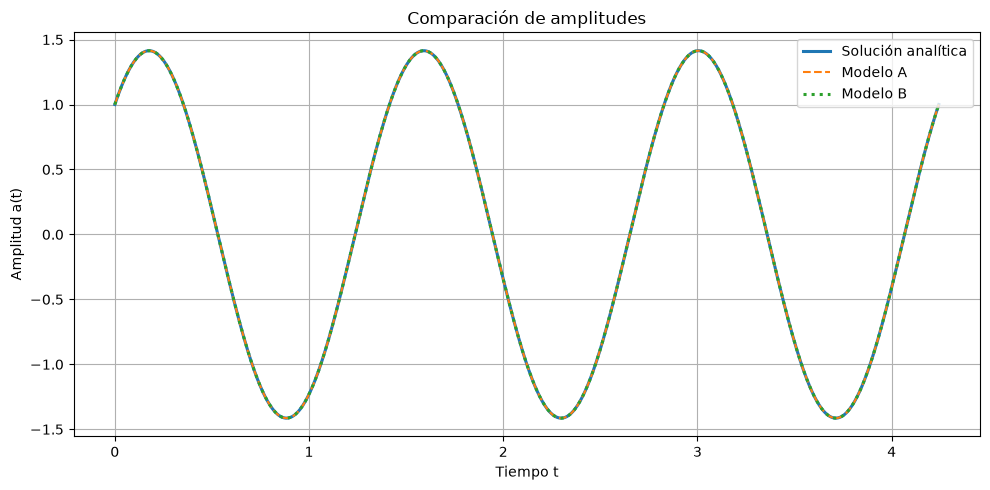

In [12]:
a_A = model_A(params_A, t)
a_B = model_B(params_B, t)
r_A = residual_A(params_A, t)
r_B = residual_B(params_B, t)

plt.figure(figsize=(10, 5))
plt.plot(t, a_reference, label="Solución analítica", linewidth=2.2)
plt.plot(t, a_A, "--", label="Modelo A")
plt.plot(t, a_B, ":", label="Modelo B", linewidth=2.2)
plt.xlabel("Tiempo t")
plt.ylabel("Amplitud a(t)")
plt.title("Comparación de amplitudes")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()



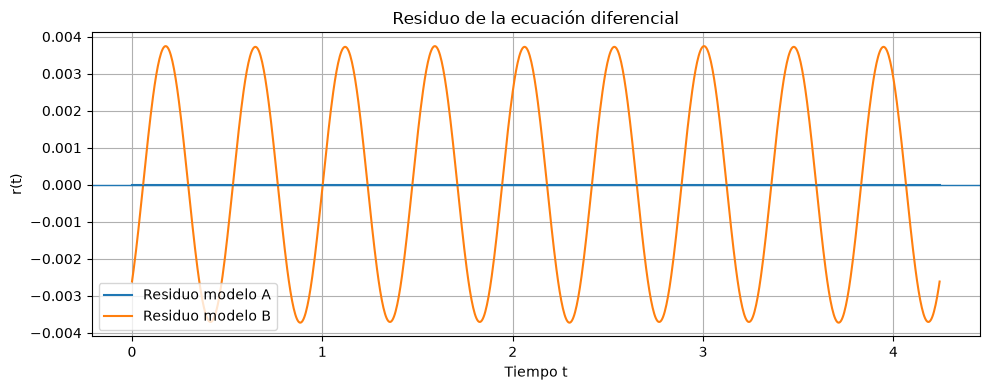

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(t, r_A, label="Residuo modelo A")
plt.plot(t, r_B, label="Residuo modelo B")
plt.axhline(0, linewidth=1)
plt.xlabel("Tiempo t")
plt.ylabel("r(t)")
plt.title("Residuo de la ecuación diferencial")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Análisis

El modelo A puede representar exactamente la solución porque esta es una sinusoide. De hecho,

$$
a(t)=\sqrt{2}\sin\left(\sqrt{2}\pi t+\frac{\pi}{4}\right),
$$

que está contenida en la arquitectura A (una neurona puede tener amplitud $\sqrt{2}$ y la otra amplitud cero).

El modelo B es una composición de senos. Su parametrización puede ser más difícil de optimizar ya que en un régimen de $w_2$ pequeño, $A$ puede crecer mientras $w_2$ disminuye, conservando aproximadamente $Aw_2$. Por eso los parámetros pueden ser sensibles a la inicialización y a los límites numéricos impuestos.

